In [1]:
import aotools
import random
import numpy as np
import free_space_fibre_overlap_sim as sim
%matplotlib widget


In [2]:
%matplotlib widget
import ipywidgets as W
from IPython.display import display
print("ipywidgets:", W.__version__)
display(W.FloatSlider(description="works?"))

ipywidgets: 8.1.5


FloatSlider(value=0.0, description='works?')

In [5]:
pixels=4*1024
zernike_array1 = [aotools.zernike_noll(1, pixels),aotools.zernike_nm(1, -1, pixels),aotools.zernike_nm(1, 1, pixels),aotools.zernike_nm(2, -2, pixels),aotools.zernike_nm(2, 0, pixels),aotools.zernike_nm(2, 2, pixels),aotools.zernike_nm(3,-3, pixels),aotools.zernike_nm(3, -1, pixels),aotools.zernike_nm(3, 1, pixels),aotools.zernike_nm(3, 3, pixels),aotools.zernike_nm(4, -4, pixels),aotools.zernike_nm(4, -2, pixels),aotools.zernike_nm(4, 0, pixels),aotools.zernike_nm(4, 2, pixels),aotools.zernike_nm(4, 4, pixels)]


In [6]:
np.save("fixedzernike_stack.npy",zernike_array1)

In [13]:
n=16
zernike_array = aotools.zernikeArray(n, 1024)

In [15]:
rand_coeff=[]
for i in range(n):
    rand_coeff.append(random.uniform(-1, 1))

In [17]:
newzernike=zernike_array[0]
newzernike

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [19]:
for i in range(len(zernike_array)):
    newzernike=newzernike+(rand_coeff[i]*zernike_array[i])

In [21]:
np.save('newzernike.npy', newzernike)

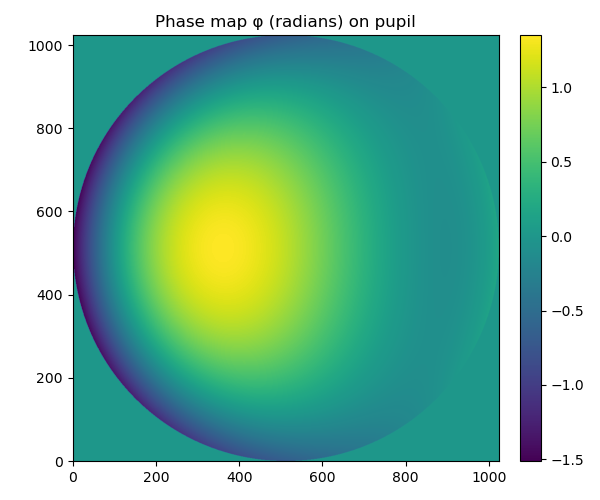

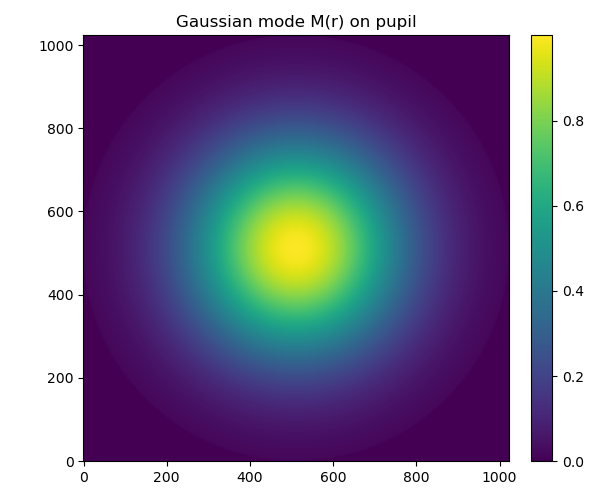

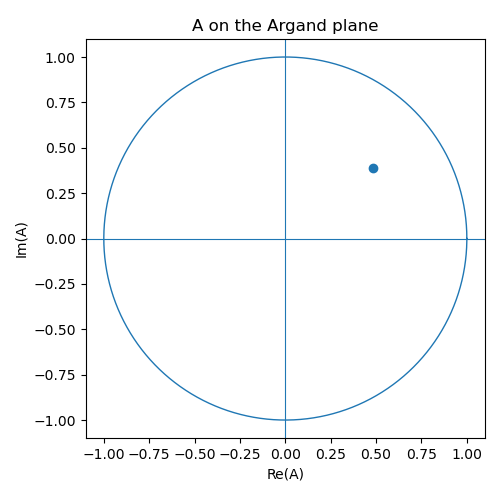

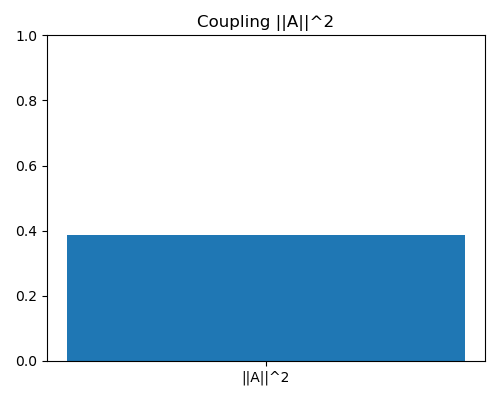

In [23]:
import numpy as np, aotools
u0 = 0.5                  # Gaussian radius as a fraction of pupil radius
Z = aotools.zernikeArray(16, 1024)  # shape (8,1024,1024) typically
np.save("newzernike_stack.npy", Z)
# then:
results = sim.simulate_from_file("newzernike_stack.npy",
                                 coeffs=[0.2, -0.5, 0.3],
                                 active_indices=[0, 3, 7],
                                 u0=u0)


In [25]:

print("Re(A) =", results["A_real"])
print("Im(A) =", results["A_imag"])
print("arg(A) =", results["A_arg"])
print("||A||^2 =", results["A_coupling"])

Re(A) = 0.4853173526794511
Im(A) = 0.38883281662521285
arg(A) = 0.6754678963890118
||A||^2 = 0.3867238920964871


In [27]:
# --- Live 15-term Zernike control UI ---
# Requires: ipywidgets, matplotlib, numpy, and the module free_space_fibre_overlap_sim.py (v1.1)

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Widgets
import ipywidgets as W
from IPython.display import display, clear_output

# Import the simulator helpers from the file you saved earlier
import importlib.util, sys
mod_path = Path("free_space_fibre_overlap_sim.py")
spec = importlib.util.spec_from_file_location("fsf", str(mod_path))
fsf = importlib.util.module_from_spec(spec)
sys.modules["fsf"] = fsf
spec.loader.exec_module(fsf)

# Choose your Zernike .npy path:
candidate_paths = [
    "newzernike_stack.npy",   # a stack with >= 15 modes
    "newzernike.npy",         # single mode or custom file
]
for p in candidate_paths:
    if Path(p).exists():
        zpath = p
        break
else:
    raise FileNotFoundError("Set `zpath` to your .npy stack (e.g. 'newzernike_stack.npy') and re-run.")

stack = fsf.load_zernike_stack(zpath)   # (K, N, N)
K, N, _ = stack.shape
Ksel = min(15, K)

X, Y, R, MASK, dA = fsf.unit_disk_grid(N)

# --- Widgets ---
u0_slider = W.FloatSlider(value=0.30, min=0.05, max=0.80, step=0.005,
                          description="u0", continuous_update=True, readout=True)

coeff_sliders = [
    W.FloatSlider(value=0.0, min=-3.14, max=3.14, step=0.01,
                  description=f"j{j+1}", continuous_update=True, readout=True,
                  layout=W.Layout(width="300px"))
    for j in range(Ksel)
]

reset_btn  = W.Button(description="Zero all", tooltip="Set all coefficients to 0")
random_btn = W.Button(description="Randomize", tooltip="Random coefficients in [-1,1] rad")
info_lbl   = W.HTML(value=f"<b>File:</b> {zpath} &nbsp; | &nbsp; "
                         f"<b>Modes loaded:</b> {K} &nbsp; | &nbsp; "
                         f"<b>Pupil N:</b> {N}")

def draw_all(coeffs, u0):
    # Combine first Ksel modes with current coeffs
    if Ksel > 0:
        phi = (coeffs[:Ksel, None, None] * stack[:Ksel]).sum(axis=0)
    else:
        phi = np.zeros((N, N), dtype=np.float64)

    phi_masked = np.zeros_like(phi)
    phi_masked[MASK] = phi[MASK]

    M = fsf.gaussian_mode_on_pupil(R, MASK, u0)
    A, nE, nM = fsf.overlap_A(phi_masked, MASK, M, dA)

    # Numeric readout
    clear_output(wait=True)
    print(f"Re(A) = {np.real(A): .6f}")
    print(f"Im(A) = {np.imag(A): .6f}")
    print(f"arg(A) [rad] = {np.angle(A): .6f}")
    print(f"||A||^2 = {np.abs(A)**2: .6f}")

    # 1) Phase heatmap (own figure)
    plt.figure(figsize=(6, 5))
    im = plt.imshow(phi_masked, origin="lower")
    plt.title("Phase map φ (radians) on pupil")
    plt.colorbar(im, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()

    # 2) Argand plot (own figure)
    plt.figure(figsize=(5, 5))
    t = np.linspace(0, 2*np.pi, 512)
    plt.plot(np.cos(t), np.sin(t), linewidth=1.0)     # unit circle
    plt.scatter([np.real(A)], [np.imag(A)])
    plt.axhline(0, linewidth=0.8)
    plt.axvline(0, linewidth=0.8)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.xlabel("Re(A)")
    plt.ylabel("Im(A)")
    plt.title("A on the Argand plane")
    plt.tight_layout()
    plt.show()

    # 3) Re/Im bar chart (own figure)
    plt.figure(figsize=(5, 4))
    plt.bar(["Re(A)", "Im(A)"], [np.real(A), np.imag(A)])
    plt.title("Real and Imaginary parts of A")
    plt.tight_layout()
    plt.show()

    # 4) Coupling bar (own figure)
    plt.figure(figsize=(5, 4))
    plt.bar(["||A||^2"], [np.abs(A)**2])
    plt.ylim(0, 1)
    plt.title("Coupling ||A||^2")
    plt.tight_layout()
    plt.show()

def on_reset_clicked(_):
    for s in coeff_sliders:
        s.value = 0.0

def on_random_clicked(_):
    rng = np.random.default_rng()
    for s in coeff_sliders:
        s.value = float(rng.uniform(-1.0, 1.0))

reset_btn.on_click(on_reset_clicked)
random_btn.on_click(on_random_clicked)

controls = {"u0": u0_slider}
for j, s in enumerate(coeff_sliders):
    controls[f"c{j}"] = s

def _callback(**kwargs):
    u0 = kwargs["u0"]
    coeffs = np.array([kwargs[f"c{j}"] for j in range(Ksel)], dtype=np.float64)
    draw_all(coeffs, u0)

io = W.interactive_output(_callback, controls)

rows = [W.HBox(coeff_sliders[r:r+5]) for r in range(0, Ksel, 5)]
top_row = W.HBox([u0_slider, reset_btn, random_btn])
ui = W.VBox([info_lbl, top_row] + rows)

display(ui, io)


Output()

In [35]:
import ipywidgets as W
from IPython.display import display
display(W.FloatSlider(description="works?"))

FloatSlider(value=0.0, description='works?')